<h1><center>Task 2 — Customer Churn Analysis</h1>

<h3>Importing Required Libraries:</h3>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("All required libraries imported successfully!")

All required libraries imported successfully!


<h3>Loading the Dataset:</h3>

In [8]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Dataset loaded successfully!")
df

Dataset loaded successfully!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


<h3>Checking the Dataset Dimensions:</h3>

In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 7043
Number of columns: 21
Dataset shape: (7043, 21)


<h3>Checking column Names and Datatypes:</h3>

In [10]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

<h3>Checking Missing Values:</h3>

In [11]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values: 0


<h3>Checking Duplicate Rows:</h3>

In [12]:
duplicate_count = df.duplicated().sum()
print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


<h3>Checking unique Values in Important Columns:</h3>

In [13]:
columns_to_check = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "Contract",
    "PaymentMethod",
    "Churn"
]

for column in columns_to_check:
    print(f"\n{column}:")
    print(df[column].value_counts())



gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


<h2><center>Cleaning and preparing the Dataset:</h3>

<h4>Checking blank spaces in Totalcharges:</h4>

In [15]:
blank_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()
print("Blank TotalCharges values:", blank_charges)

Blank TotalCharges values: 11


<h4>Converting Totalcharges into a Numeric Column:</h4>

In [16]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

TotalCharges data type: float64
Missing TotalCharges after conversion: 11


<h4>Handling any Missing Totalcharges Values:</h4>

In [17]:
missing_charges = df["TotalCharges"].isnull().sum()
print("Missing TotalCharges before cleaning:", missing_charges)
if missing_charges > 0:
    df = df.dropna(subset=["TotalCharges"]).copy()

print("Missing TotalCharges after cleaning:", df["TotalCharges"].isnull().sum())
print("Dataset shape after cleaning:", df.shape)

Missing TotalCharges before cleaning: 11
Missing TotalCharges after cleaning: 0
Dataset shape after cleaning: (7032, 21)


<h4>Verifying The Cleaned Dataset:</h4>

In [18]:
print("Dataset Information:")
df.info()
print("\nTotal missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<h2><center>Exploratory Data Analysis (EDA)</h2>

<h3>Calculating the overall Churn Rate:</h3>

In [19]:
churn_counts = df["Churn"].value_counts()

print("Customer Churn Count:")
print(churn_counts)

total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
churn_rate = (churned_customers / total_customers) * 100

print("\nTotal Customers:", total_customers)
print("Customers Who Left:", churned_customers)
print("Overall Churn Rate:", round(churn_rate, 2), "%")

Customer Churn Count:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Total Customers: 7032
Customers Who Left: 1869
Overall Churn Rate: 26.58 %


<h3>Customer Churn Distribution:</h3>

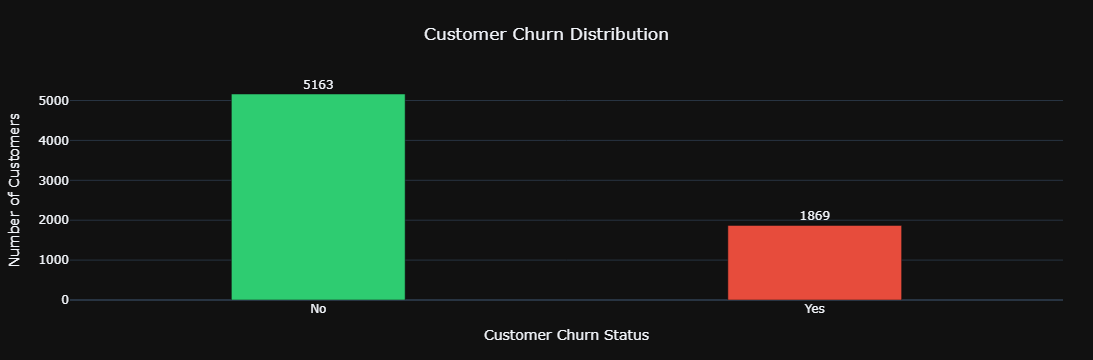

In [25]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"]).reset_index()
churn_counts.columns = ["Churn", "Number of Customers"]

fig = px.bar(
    churn_counts,
    x="Churn",
    y="Number of Customers",
    color="Churn",
    text="Number of Customers",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Churn Distribution",
    template="plotly_dark"
)

fig.update_traces(
    width=0.35,
    textposition="outside",
    cliponaxis=False,
    hovertemplate="Status: %{x}<br>Customers: %{y:,}<extra></extra>"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Churn Status",
    yaxis_title="Number of Customers",
    showlegend=False,
    bargap=0.45,
    margin=dict(t=80, b=60, l=70, r=30)
)

fig.show()

<h3>Customer Retrention v/s Churn:</h3>

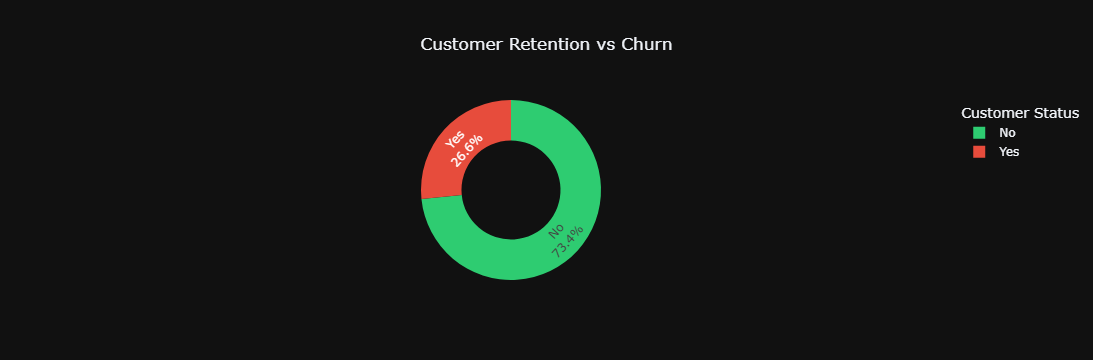

In [26]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"]).reset_index()
churn_counts.columns = ["Churn", "Number of Customers"]

fig = px.pie(
    churn_counts,
    names="Churn",
    values="Number of Customers",
    hole=0.55,
    color="Churn",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Retention vs Churn",
    template="plotly_dark"
)

fig.update_traces(
    textinfo="label+percent",
    hovertemplate="%{label}<br>Customers: %{value:,}<br>Share: %{percent}<extra></extra>",
    sort=False
)

fig.update_layout(
    title_x=0.5,
    legend_title_text="Customer Status"
)

fig.show()


<h3>Churn by Contract Type:</h3>

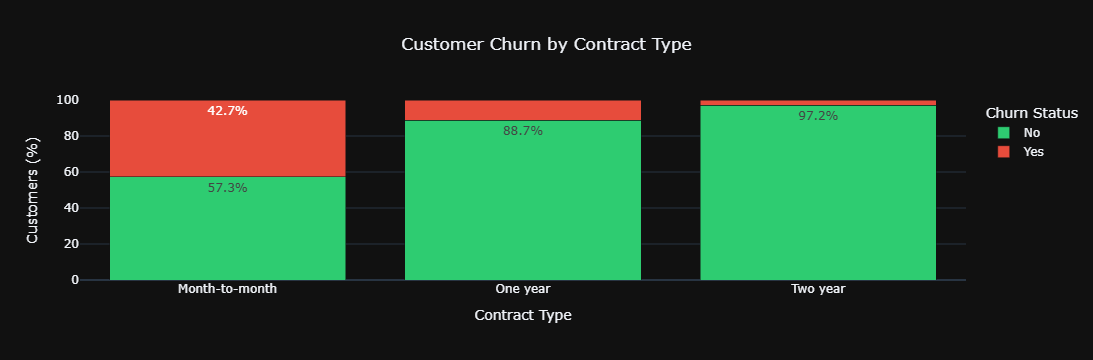

In [27]:
import pandas as pd
import plotly.express as px

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).reset_index()

contract_churn = contract_churn.melt(
    id_vars="Contract",
    var_name="Churn",
    value_name="Percentage"
)

fig = px.bar(
    contract_churn,
    x="Contract",
    y="Percentage",
    color="Churn",
    barmode="stack",
    text=contract_churn["Percentage"].round(1),
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Churn by Contract Type",
    template="plotly_dark"
)

fig.update_traces(
    texttemplate="%{text}%",
    hovertemplate=(
        "Contract: %{x}<br>"
        "Status: %{fullData.name}<br>"
        "Percentage: %{y:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Contract Type",
    yaxis_title="Customers (%)",
    yaxis_range=[0, 100],
    legend_title_text="Churn Status"
)

fig.show()

<h3>Visualizing Customer tenure:</h3>

Customer Tenure Summary:


,count,mean,median,min,max
Churn,,,,,
No,5163,37.65,38.0,1,72
Yes,1869,17.98,10.0,1,72


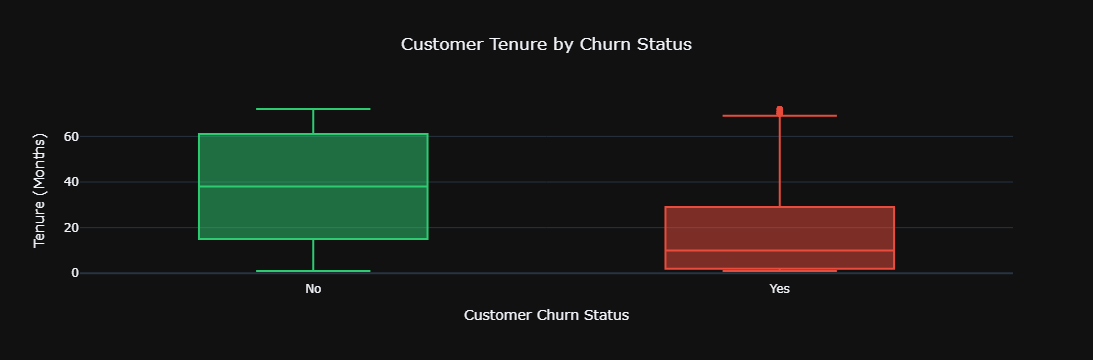

In [30]:
import plotly.express as px

tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print("Customer Tenure Summary:")
display(tenure_summary)

fig = px.box(
    df,
    x="Churn",
    y="tenure",
    color="Churn",
    points="outliers",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Tenure by Churn Status",
    labels={
        "Churn": "Customer Churn Status",
        "tenure": "Tenure (Months)"
    },
    template="plotly_dark"
)

fig.update_layout(
    title_x=0.5,
    showlegend=False
)

fig.show()

<h3>Finding:</h3>
Customers who left had a median tenure of just 10 months, compared with 38 months for customers who stayed.

<h3>Evidence:</h3>
The average tenure of churned customers was 17.98 months, while retained customers averaged 37.65 months.

<h3>Business Implication:</h3>
The average tenure of churned customers was 17.98 months, while retained customers averaged 37.65 months.

<h3>Monthly charges by churn:</h3>

Monthly Charges Summary:


,count,mean,median,min,max
Churn,,,,,
No,5163,61.31,64.45,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


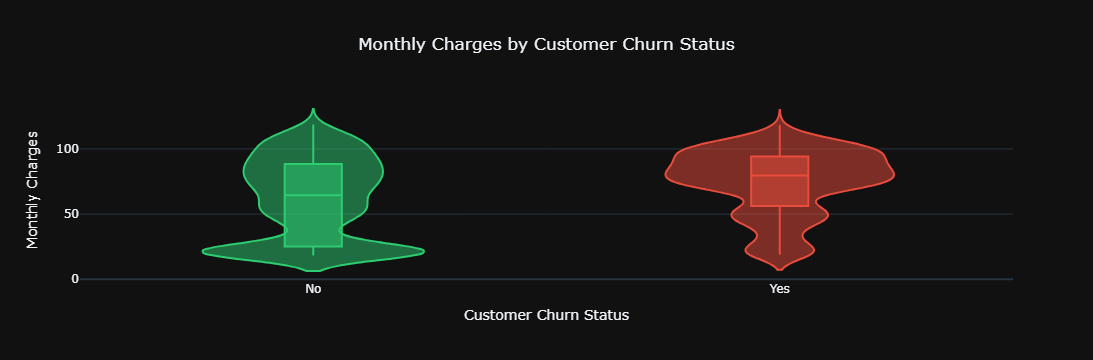

In [35]:
s_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print("Monthly Charges Summary:")
display(s_summary)

fig = px.violin(
    df,
    x="Churn",
    y="MonthlyCharges",
    color="Churn",
    box=True,
    points=False,
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Monthly Charges by Customer Churn Status",
    labels={
        "Churn": "Customer Churn Status",
        "MonthlyCharges": "Monthly Charges"
    },
    template="plotly_dark"
)

fig.update_layout(
    title_x=0.5,
    showlegend=False,
    xaxis_title="Customer Churn Status",
    yaxis_title="Monthly Charges"
)

fig.show()

### Finding:
Customers who left paid higher monthly charges on average than customers who stayed.

## Evidence:
The average monthly charge was 74.44 for churned customers, compared with 61.31 for retained customers. The median was also higher: 79.65 versus 64.45.

## Business implication:
The company could investigate whether pricing, service combinations, or perceived value are contributing to churn. These results show an association, not proof that higher charges cause customers to leave.





<h3>Payment method vs. churn:</h3>

Churn Rate by Payment Method:


Churn,Churn Rate (%)
PaymentMethod,
Bank transfer (automatic),16.73
Credit card (automatic),15.25
Electronic check,45.29
Mailed check,19.20


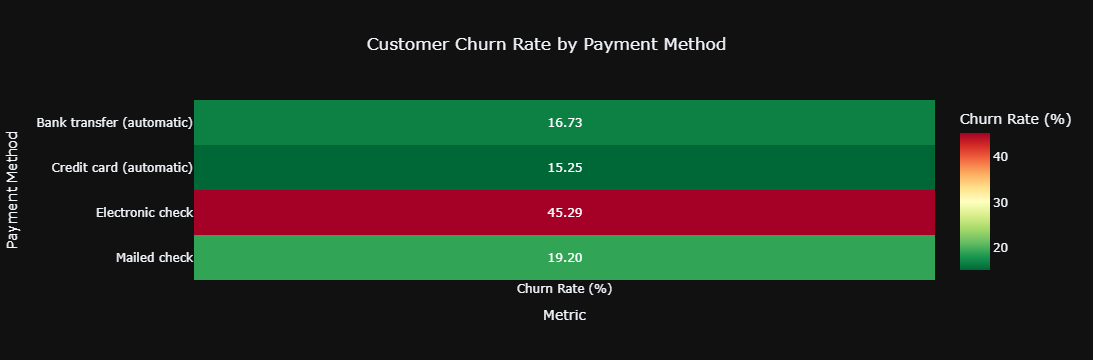

In [36]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).mul(100)

payment_churn = payment_churn[["Yes"]].rename(
    columns={"Yes": "Churn Rate (%)"}
)

print("Churn Rate by Payment Method:")
display(payment_churn.round(2))

fig = px.imshow(
    payment_churn,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="RdYlGn_r",
    title="Customer Churn Rate by Payment Method",
    labels={
        "x": "Customer Churn Metric",
        "y": "Payment Method",
        "color": "Churn Rate (%)"
    },
    template="plotly_dark"
)

fig.update_traces(
    hovertemplate=(
        "Payment Method: %{y}<br>"
        "Churn Rate: %{z:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Metric",
    yaxis_title="Payment Method"
)

fig.show()

## Finding:
Customers paying by electronic check have the highest churn rate among the four payment methods.

## Evidence:
The electronic check churn rate is 45.29%, compared with 15.25% for automatic credit card payments.

## Business implication:
The company should investigate the electronic-check customer experience, including payment friction, billing communication, and customer characteristics. These results show an association, not proof that payment method causes churn.

<h3>Tenure vs. monthly charges:</h3>

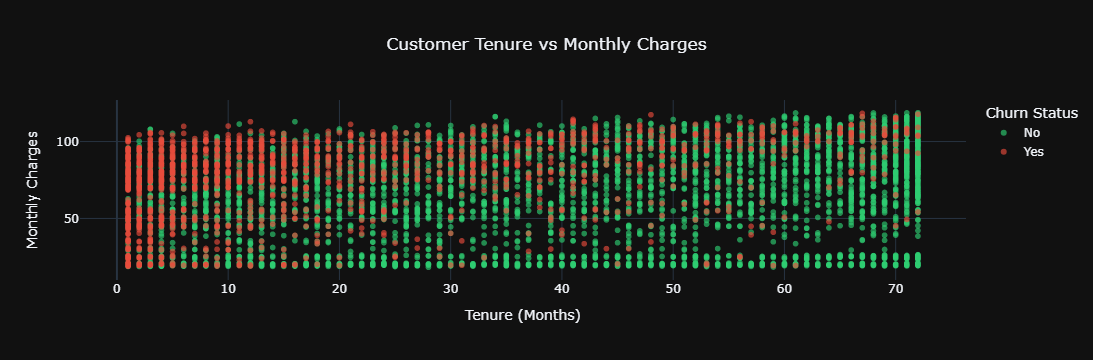

In [37]:
fig = px.scatter(
    df,
    x="tenure",
    y="MonthlyCharges",
    color="Churn",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    opacity=0.65,
    hover_data=[
        "Contract",
        "PaymentMethod",
        "InternetService",
        "TotalCharges"
    ],
    title="Customer Tenure vs Monthly Charges",
    labels={
        "tenure": "Tenure (Months)",
        "MonthlyCharges": "Monthly Charges",
        "Churn": "Customer Churn Status"
    },
    template="plotly_dark"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Tenure (Months)",
    yaxis_title="Monthly Charges",
    legend_title_text="Churn Status"
)

fig.show()

<h3>Churn by internet service:</h3>

Customer Count by Internet Service and Churn:


,InternetService,Churn,Number of Customers
0,DSL,No,1957
1,DSL,Yes,459
2,Fiber optic,No,1799
3,Fiber optic,Yes,1297
4,No,No,1407
5,No,Yes,113


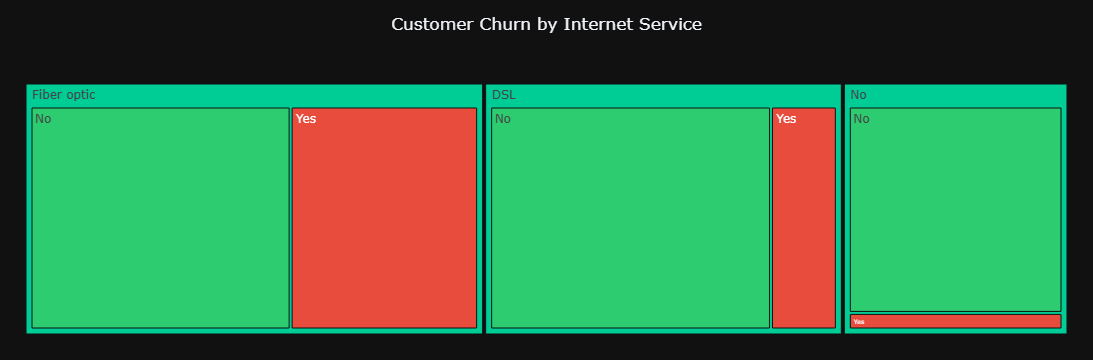

In [38]:
internet_churn = (
    df.groupby(["InternetService", "Churn"])
    .size()
    .reset_index(name="Number of Customers")
)

print("Customer Count by Internet Service and Churn:")
display(internet_churn)

fig = px.treemap(
    internet_churn,
    path=["InternetService", "Churn"],
    values="Number of Customers",
    color="Churn",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Churn by Internet Service",
    template="plotly_dark"
)

fig.update_layout(
    title_x=0.5,
    margin=dict(t=60, l=20, r=20, b=20)
)

fig.show()

## Finding:
Fiber optic customers have the highest churn rate among the three internet-service groups.


## Evidence:
Approximately 41.9% of fiber optic customers left, compared with 19.0% of DSL customers and 7.4% of customers without internet service.


## Business implication:
The company should investigate fiber optic customers' service quality, pricing, and support experience to identify potential reasons for the higher churn rate. These figures show an association, not proof of a cause.

<h3>Churn by senior-citizen status:</h3>

Churn Percentage by Senior Citizen Status:


,SeniorCitizenStatus,Churn,Percentage
0,Non-Senior Citizen,No,76.35
1,Senior Citizen,No,58.32
2,Non-Senior Citizen,Yes,23.65
3,Senior Citizen,Yes,41.68


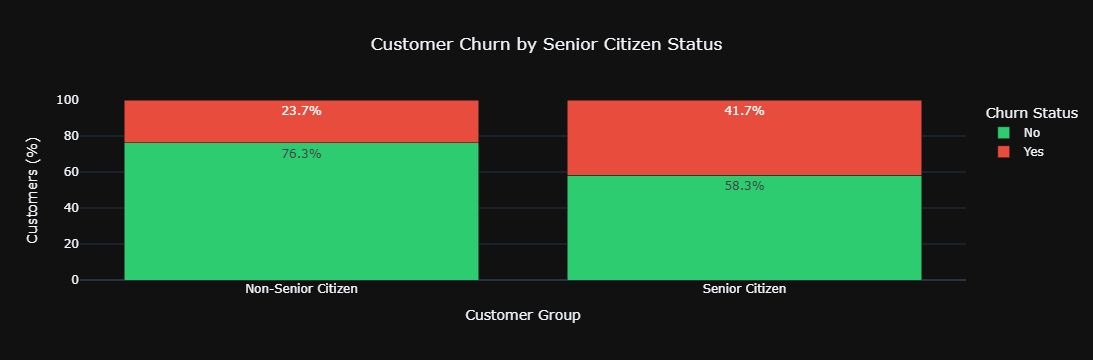

In [39]:
df["SeniorCitizenStatus"] = df["SeniorCitizen"].map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

senior_churn = pd.crosstab(
    df["SeniorCitizenStatus"],
    df["Churn"],
    normalize="index"
).mul(100).reset_index()

senior_churn = senior_churn.melt(
    id_vars="SeniorCitizenStatus",
    var_name="Churn",
    value_name="Percentage"
)

print("Churn Percentage by Senior Citizen Status:")
display(senior_churn.round(2))

fig = px.bar(
    senior_churn,
    x="SeniorCitizenStatus",
    y="Percentage",
    color="Churn",
    barmode="stack",
    text=senior_churn["Percentage"].round(1),
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Churn by Senior Citizen Status",
    labels={
        "SeniorCitizenStatus": "Customer Group",
        "Percentage": "Customers (%)"
    },
    template="plotly_dark"
)

fig.update_traces(
    texttemplate="%{text}%",
    hovertemplate=(
        "Group: %{x}<br>"
        "Churn status: %{fullData.name}<br>"
        "Percentage: %{y:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    title_x=0.5,
    yaxis_range=[0, 100],
    showlegend=True,
    legend_title_text="Churn Status"
)

fig.show()

## Finding:
Senior citizens have a higher churn rate than non-senior citizens.

## Evidence:
The churn rate is 41.68% for senior citizens, compared with 23.65% for non-senior citizens — an 18.03 percentage-point difference.

## Business implication:
The company could investigate whether senior customers need more accessible support, clearer billing information, or service plans that better fit their needs. The chart identifies an association, not the reason for it.

<h3>Churn by contract and internet service:</h3> 

Customer counts by contract, internet service, and churn:


,Contract,InternetService,Churn,Number of Customers
0,Month-to-month,DSL,No,829
1,Month-to-month,DSL,Yes,394
2,Month-to-month,Fiber optic,No,966
3,Month-to-month,Fiber optic,Yes,1162
4,Month-to-month,No,No,425
5,Month-to-month,No,Yes,99
6,One year,DSL,No,517
7,One year,DSL,Yes,53
8,One year,Fiber optic,No,435
9,One year,Fiber optic,Yes,104


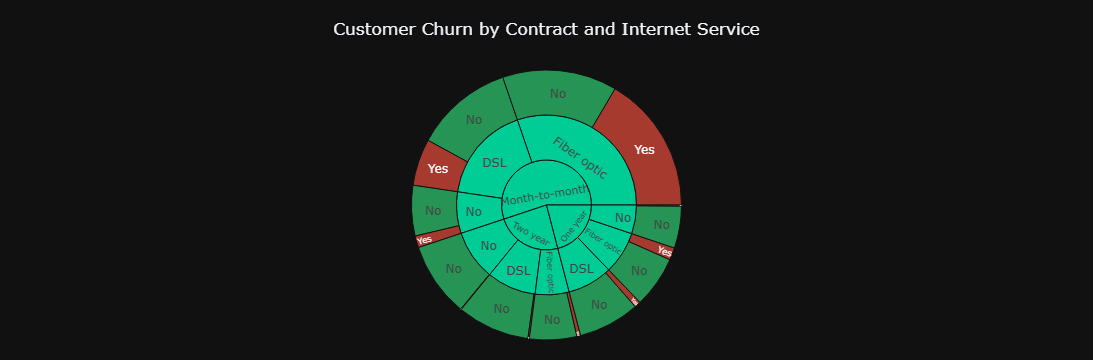

In [40]:
sunburst_data = (
    df.groupby(["Contract", "InternetService", "Churn"])
    .size()
    .reset_index(name="Number of Customers")
)

print("Customer counts by contract, internet service, and churn:")
display(sunburst_data.head(10))

fig = px.sunburst(
    sunburst_data,
    path=["Contract", "InternetService", "Churn"],
    values="Number of Customers",
    color="Churn",
    color_discrete_map={
        "No": "#2ECC71",
        "Yes": "#E74C3C"
    },
    title="Customer Churn by Contract and Internet Service",
    template="plotly_dark"
)

fig.update_layout(
    title_x=0.5,
    margin=dict(t=70, l=20, r=20, b=20)
)

fig.show()

## Finding:
Month-to-month customers using fiber optic internet have particularly high churn.

## Evidence:
In this group, 1,162 customers left while 966 stayed, giving a churn rate of approximately 54.60%.

## Business implication:
The company should investigate fiber optic pricing, service quality, and customer support, and consider targeted retention offers for month-to-month fiber optic customers.

<h3>Churn rate by contract type:</h3>

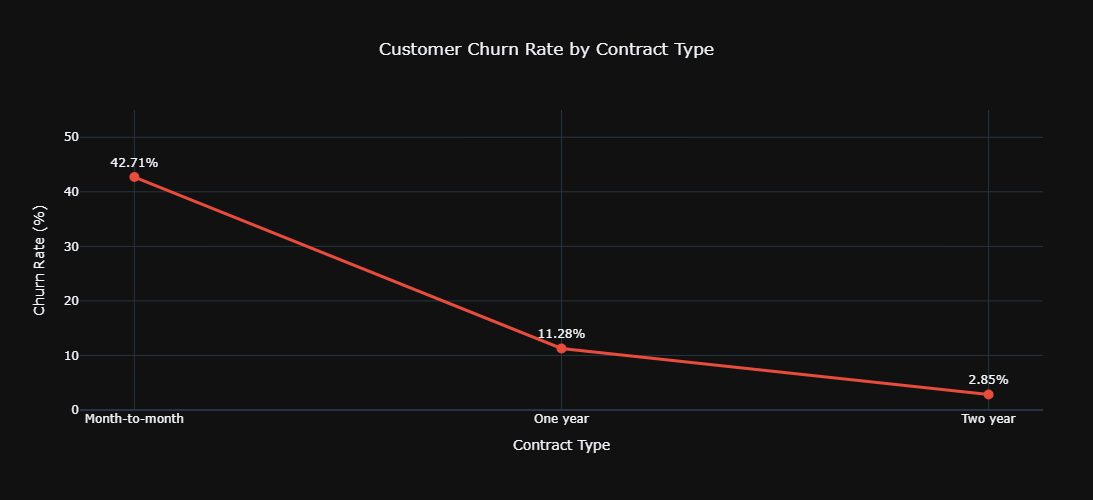

In [43]:
fig = px.line(
    contract_churn,
    x="Contract",
    y="Churn Rate (%)",
    markers=True,
    text=contract_churn["Churn Rate (%)"].round(2),
    title="Customer Churn Rate by Contract Type",
    labels={
        "Contract": "Contract Type",
        "Churn Rate (%)": "Churn Rate (%)"
    },
    template="plotly_dark"
)

fig.update_traces(
    line=dict(color="#E74C3C", width=3),
    marker=dict(size=10, color="#E74C3C"),
    texttemplate="%{text}%",
    textposition="top center",
    cliponaxis=False,
    hovertemplate=(
        "Contract: %{x}<br>"
        "Churn Rate: %{y:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    title_x=0.5,
    height=500,
    margin=dict(t=110, b=90, l=80, r=50),
    yaxis=dict(
        title="Churn Rate (%)",
        range=[0, 55]
    ),
    xaxis_title="Contract Type"
)

fig.show()

## Finding:
Customers on month-to-month contracts have the highest churn rate.

## Evidence:
The churn rate is 42.71% for month-to-month contracts, compared with 11.28% for one-year contracts and 2.85% for two-year contracts. Month-to-month churn is approximately 15 times the two-year churn rate.

## Business implication:
The company should investigate targeted retention offers and suitable longer-term plans for month-to-month customers. These results show an association between contract type and churn, not proof of causation.

<h3>Calculating Business KPIs:</h3>

In [44]:
total_customers = df["customerID"].nunique()

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

average_tenure = df["tenure"].mean()

average_monthly_charges = df["MonthlyCharges"].mean()

average_total_charges = df["TotalCharges"].mean()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Churn Rate (%)",
        "Retention Rate (%)",
        "Average Tenure (Months)",
        "Average Monthly Charges",
        "Average Total Charges"
    ],
    "Value": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate, 2),
        round(retention_rate, 2),
        round(average_tenure, 2),
        round(average_monthly_charges, 2),
        round(average_total_charges, 2)
    ]
})

print("KEY CUSTOMER CHURN KPIs")
display(kpi_summary)

KEY CUSTOMER CHURN KPIs


,KPI,Value
0,Total Customers,7032.00
1,Churned Customers,1869.00
2,Retained Customers,5163.00
3,Churn Rate (%),26.58
4,Retention Rate (%),73.42
5,Average Tenure (Months),32.42
6,Average Monthly Charges,64.80
7,Average Total Charges,2283.30


## Key Findings:

1. **A considerable number of customers left the service.** Out of 7,032 customers in the cleaned dataset, 1,869 had left the service. This represents a churn rate of 26.58%, while 73.42% of customers stayed.

2. **Month-to-month customers were more likely to leave.** The churn rate for month-to-month customers was 42.71%, compared with 11.28% for one-year contracts and 2.85% for two-year contracts. This shows a clear relationship between contract type and customer churn.

3. **Customers who left generally had shorter tenures.** The median tenure of customers who left was 10 months, whereas customers who stayed had a median tenure of 38 months. This suggests that retaining customers during the early stages of their relationship is particularly important.

4. **Customers who left paid higher monthly charges on average.** The average monthly charge for churned customers was 74.44, compared with 61.31 for customers who stayed. This pattern suggests that pricing and the value customers receive from the service may be worth investigating.

5. **Electronic-check users had the highest churn rate among payment methods.** Their churn rate was 45.29%, compared with 15.25% for customers using automatic credit card payments. The company could investigate whether payment-related issues or other customer characteristics are associated with this difference.

6. **Fiber optic customers showed higher churn.** Approximately 41.9% of fiber optic customers left the service, compared with 19.0% of DSL customers and 7.4% of customers without internet service. Further investigation could help the company understand the reasons behind this pattern.

7. **Senior citizens had a higher churn rate than non-senior citizens.** The churn rate was 41.68% among senior citizens and 23.65% among non-senior citizens. This difference highlights a customer group whose service experience may deserve further attention.

8. **Some customer groups showed particularly high churn.** The combination of month-to-month contracts and fiber optic internet had a churn rate of approximately 54.6% in the analysed dataset. This suggests that examining multiple customer characteristics together can reveal patterns that may not be obvious when looking at each factor separately.

## Recommendations:

Focus on month-to-month customers. These customers are more likely to leave, so the company could offer suitable long-term plans, loyalty benefits, or special offers to encourage them to stay.

Pay more attention to new customers. The company should regularly check whether new customers are satisfied with the service and help them resolve any problems early.

Look into electronic-check payments. Customers using electronic checks have a higher churn rate. The company should try to understand whether billing issues, payment difficulties, or other concerns are contributing to this pattern.

Improve the fiber optic customer experience. The company should review customer feedback about fiber optic services, including pricing, internet quality, and technical support, to understand why more customers in this group are leaving.

Make support easier for senior customers. Clear billing information and accessible customer support may help senior customers get assistance when they need it.

Keep track of customer churn regularly. The company should monitor churn rate, retention rate, contract types, customer tenure, payment methods, and internet services to identify changes in customer behaviour.

Check whether the suggested actions work. Before making major changes, the company should collect customer feedback and test different retention offers to see which ones actually encourage customers to stay.

## Customer Churn Analysis — Conclusion:

In this project, I analysed customer data to understand why some customers leave a service while others continue using it. I used Python, Pandas, and Plotly to clean the data, explore customer behaviour, calculate key performance indicators (KPIs), and create interactive visualizations.

After cleaning the dataset, I worked with 7,032 customer records. Out of these, 1,869 customers had left the service, giving an overall churn rate of 26.58%. The remaining 5,163 customers stayed, resulting in a retention rate of 73.42%.

During the analysis, I found that customers on month-to-month contracts were much more likely to leave than those on one-year or two-year contracts. Customers who left also tended to have shorter relationships with the company and higher average monthly charges. I also noticed higher churn rates among customers using electronic checks and fiber optic internet, as well as among senior citizens.

These findings helped me identify the customer groups that may need more attention. The company could focus on improving the experience of new customers, reviewing pricing and service concerns, and offering suitable retention benefits to customers who may be more likely to leave.

Overall, this project helped me understand how data analysis can be used to identify customer behaviour patterns and turn them into useful business insights. The results do not prove the exact reasons why customers leave, but they provide a good starting point for further investigation and better customer retention strategies.

In [2]:
from pathlib import Path

folder = Path(r"C:\Users\itsme\OneDrive\Desktop\FUTURE_DS_02")

print("Folder exists:", folder.exists())

if folder.exists():
    print("\nFiles in your project folder:")
    for file in folder.iterdir():
        print(file.name)

Folder exists: True

Files in your project folder:
.ipynb_checkpoints
app.py
Customer_Churn_Analysis.ipynb
Requirements.txt
Telco-Customer-Churn.csv


In [ ]:
!python -m streamlit run "C:/Users/itsme/OneDrive/Desktop/FUTURE_DS_02/app.py"